In [1]:
# Setup: loads the saved results of the main notebook. This cell is not shown in the slides.
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA, MODELS = ROOT / "data" / "processed", ROOT / "models"

segments = pd.read_csv(DATA / "customer_segments.csv", index_col=0)
scaled = pd.read_csv(DATA / "customer_features_scaled.csv", index_col=0)
kmeans_scores = pd.read_csv(MODELS / "kmeans_scores_by_k.csv", index_col=0)
hier_scores = pd.read_csv(MODELS / "hierarchical_scores_by_k.csv", index_col=0)
comparison = pd.read_csv(MODELS / "model_comparison.csv", index_col=0)
config = json.loads((MODELS / "model_config.json").read_text())
FEATURES = config["features"]
ORDER = ["Loyal Regulars", "New Customers", "Lapsed Customers", "Heavy Returners"]

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_SOFT, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white", "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 11,
    "text.color": INK, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
})
sequential = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
diverging = LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"])

def heatmap(table, cmap, vmin, vmax, fmt, title, label, figsize=(10, 3.4), white_above=None):
    fig, ax = plt.subplots(figsize=figsize)
    image = ax.imshow(table, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns); ax.set_yticks(range(table.shape[0]), table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.iat[i, j]
            ax.text(j, i, format(v, fmt), ha="center", va="center", fontsize=10,
                    color="white" if white_above is not None and abs(v) > white_above else INK)
    ax.set_xticks(np.arange(-0.5, table.shape[1]), minor=True); ax.set_yticks(np.arange(-0.5, table.shape[0]), minor=True)
    ax.grid(False); ax.grid(which="minor", color="white", linewidth=2); ax.tick_params(which="both", length=0)
    for s in ax.spines.values(): s.set_visible(False)
    bar = fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02); bar.set_label(label, color=INK_SOFT, fontsize=9); bar.outline.set_visible(False)
    ax.set_title(title); plt.tight_layout(); plt.show()

<style>
.reveal { font-size: 24px; }
.reveal h1 { font-size: 2.0em; } .reveal h2 { font-size: 1.45em; } .reveal h3 { font-size: 1.05em; color: #52514e; font-weight: normal; }
.reveal table { font-size: 0.78em; margin: 0.4em 0; } .reveal li { margin-bottom: 0.25em; }
.reveal .jp-RenderedImage img, .reveal .output_png img { max-height: 430px; }
.reveal section { text-align: left; }
</style>

# Customer Segmentation for an Online Retailer

### Technical presentation: unsupervised clustering on the UCI Online Retail II dataset

**Frederick Halog** &nbsp;|&nbsp; AIM Capstone Project

<small>Data: Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D (CC BY 4.0)</small>

## 1. Problem framing

**Business problem.** All customers receive the same marketing. The top 20% of customers generate 77% of sales, and nobody is treating them differently.

**Data science task.** Unsupervised clustering of customers on behavioural features. No labels exist.

| | |
|---|---|
| **Unit of analysis** | One row per customer (5,852 after cleaning) |
| **Candidate models** | K-Means, Agglomerative (Ward), DBSCAN |
| **Primary metric** | Silhouette Score |
| **Supporting metrics** | Davies-Bouldin, Calinski-Harabasz |
| **Practical checks** | Segment sizes, stability across seeds (ARI), interpretability |
| **Selection rule** | Best Silhouette with k between 3 and 6; k from 2 to 10 reported for transparency |

## 2. Data and cleaning

1,044,848 invoice lines, Dec 2009 to Dec 2011, two Excel sheets merged (22,523 overlapping rows de-duplicated).

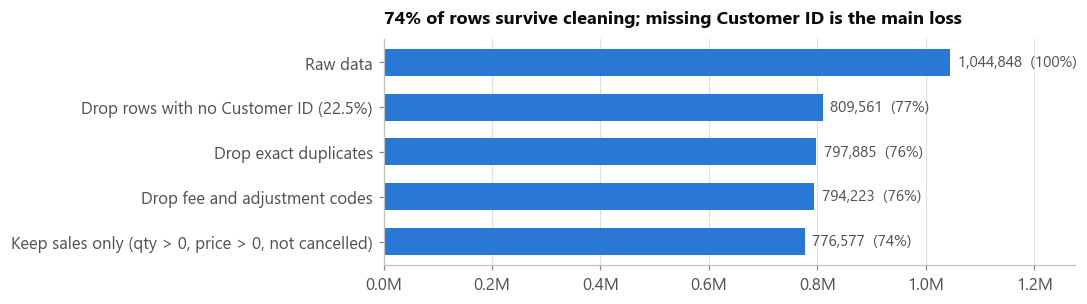

In [2]:
# Row counts after each cleaning step, taken from section 3.1 of the main notebook
steps = pd.Series({
    "Raw data": 1_044_848,
    "Drop rows with no Customer ID (22.5%)": 809_561,
    "Drop exact duplicates": 797_885,
    "Drop fee and adjustment codes": 794_223,
    "Keep sales only (qty > 0, price > 0, not cancelled)": 776_577,
})[::-1]
fig, ax = plt.subplots(figsize=(10, 2.9))
bars = ax.barh(steps.index, steps.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:,}  ({v / 1_044_848:.0%})" for v in steps.values], padding=5, color=INK_SOFT, fontsize=10)
ax.set_title("74% of rows survive cleaning; missing Customer ID is the main loss")
ax.set_xlim(0, 1_044_848 * 1.22); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e6:.1f}M"))
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

- Cancellations (17,586 lines) are kept in a separate table and become a **ReturnRate** feature.
- Missingness is not random: 24% of UK rows lack a Customer ID against 3.5% of non-UK rows (selection bias, revisited later).

## 3. Feature engineering

**10 candidate features per customer**, with RFM at the core. Reference date: 10 Dec 2011.

| Group | Features |
|---|---|
| **RFM** | Recency (days), Frequency (invoices), Monetary (£) |
| **Basket** | AvgOrderValue, TotalUnits, UniqueProducts, ProductsPerOrder, AvgUnitPrice |
| **Lifecycle and returns** | Tenure (days), ReturnRate (£ returned / £ bought) |

**Outlier treatment (no customers removed)**

| Step | Detail | Effect |
|---|---|---|
| Winsorise | Cap each feature at its 99th percentile | About 59 customers capped per feature |
| Log transform | `log1p` where skewness > 1 after capping (8 of 10 features) | Monetary skew 25.3 to 0.12; AvgOrderValue 53.4 to -0.31 |
| Standardise | `StandardScaler` on the selected features | Mean 0, std 1 |

**Also built, but excluded from the model:** RFM quintile scores (binning, used as a benchmark) and an `IsUK` flag (encoding, reserved for the fairness audit).

## 4. Feature selection and clustering tendency

**Filter method, three passes: 10 features reduced to 7**

| Filter | Rule | Outcome |
|---|---|---|
| Near-constant | Drop if more than 95% share one value | None dropped (ReturnRate closest at 59% zeros) |
| Pairwise redundancy | Spearman above 0.85; R, F, M protected | **TotalUnits** dropped (0.95 with Monetary) |
| Multicollinearity | Iteratively drop VIF above 10 | **AvgOrderValue** (VIF 29) and **UniqueProducts** (VIF 38) dropped |

- The pairwise filter missed AvgOrderValue because it equals Monetary / Frequency: a linear dependency in log space that only VIF (or PCA) exposes. Before the VIF pass, two principal components carried 0.2% of the variance between them.
- Frequency and Monetary are both retained despite Spearman 0.86. Final VIF: 5.9 and 4.7.

**Final features:** Recency, Frequency, Monetary, ProductsPerOrder, AvgUnitPrice, Tenure, ReturnRate

**Hopkins statistic: 0.83** (uniform noise baseline 0.50, 10 runs each). The data is clusterable.

## 5. Dimensionality reduction

PCA needs 5 of 7 components for 96% of variance, so we cluster on the 7 scaled features and use projections for visualisation only.

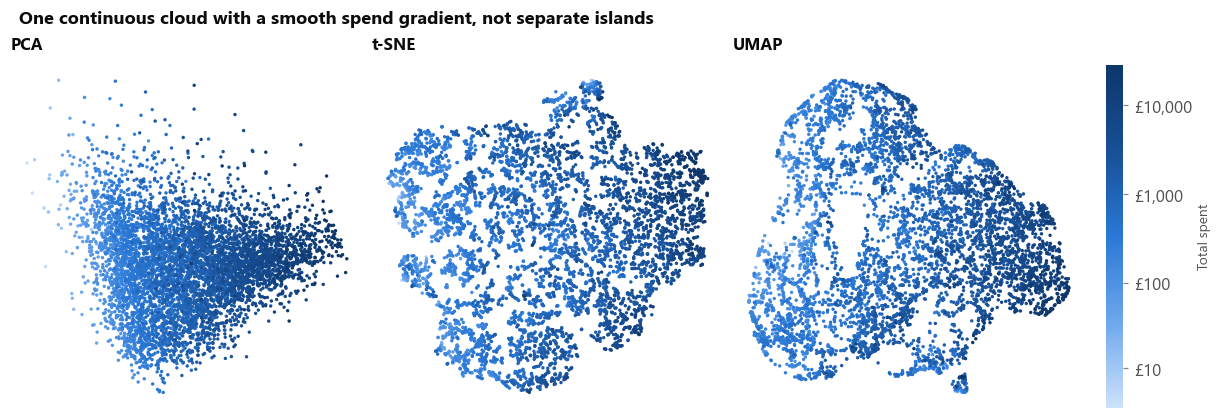

In [3]:
shade = np.log1p(segments["Monetary"].clip(upper=segments["Monetary"].quantile(0.99)))
order = shade.argsort().values
fig, axes = plt.subplots(1, 3, figsize=(11, 3.7), constrained_layout=True)
for ax, name in zip(axes, ["PCA", "t-SNE", "UMAP"]):
    dots = ax.scatter(segments[f"{name}_x"].values[order], segments[f"{name}_y"].values[order],
                      c=shade.values[order], cmap=sequential, s=5, linewidths=0)
    ax.set_title(name, fontsize=11); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
bar = fig.colorbar(dots, ax=axes, fraction=0.025, pad=0.02)
ticks = [10, 100, 1_000, 10_000]; bar.set_ticks(np.log1p(ticks)); bar.set_ticklabels([f"£{t:,}" for t in ticks])
bar.set_label("Total spent", color=INK_SOFT, fontsize=9); bar.outline.set_visible(False)
fig.suptitle("One continuous cloud with a smooth spend gradient, not separate islands", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.show()

- PC1 (35%): Frequency and Monetary (+0.60 each), Recency (-0.38). PC2 (20%): Tenure (+0.61), Recency (+0.46).
- Expectation set before modelling: moderate Silhouette, and density-based methods likely to struggle.

## 6. Choosing k

K-Means (`n_init=20`) and Ward linkage, scored for k from 2 to 10.

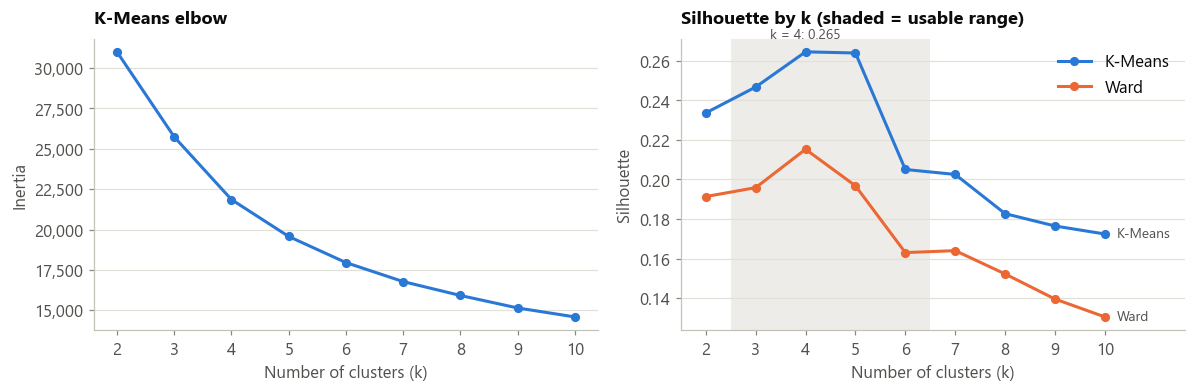

In [4]:
ks = list(kmeans_scores.index)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
ax = axes[0]
ax.plot(ks, kmeans_scores["Inertia"], color=BLUE, linewidth=2, marker="o", markersize=5)
ax.set_title("K-Means elbow"); ax.set_ylabel("Inertia"); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax = axes[1]
ax.axvspan(2.5, 6.5, color=GRID, alpha=0.6, linewidth=0)
for name, table, colour in [("K-Means", kmeans_scores, BLUE), ("Ward", hier_scores, ORANGE)]:
    ax.plot(ks, table["Silhouette"], color=colour, linewidth=2, marker="o", markersize=5, label=name)
    ax.annotate(name, xy=(ks[-1], table["Silhouette"].iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", color=INK_SOFT, fontsize=9)
ax.annotate("k = 4: 0.265", xy=(4, kmeans_scores.loc[4, "Silhouette"]), xytext=(0, 9), textcoords="offset points", ha="center", color=INK_SOFT, fontsize=9)
ax.set_title("Silhouette by k (shaded = usable range)"); ax.set_ylabel("Silhouette"); ax.set_xlim(1.5, 11.6)
ax.legend(frameon=False, loc="upper right")
for ax in axes:
    ax.set_xlabel("Number of clusters (k)"); ax.set_xticks(ks); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

- **k = 4** maximises Silhouette for both methods and is the global maximum over 2 to 10. k = 5 is a near tie for K-Means (0.264).
- Stability: Adjusted Rand Index 0.994 across 10 random seeds (minimum 0.990).

## 7. Model comparison

In [5]:
table = comparison.copy()
table.index = ["K-Means (k=4)", "Agglomerative, Ward (k=4)", "DBSCAN (eps=1.5, min_samples=7)"]
table = table.rename(columns={"Groups": "Clusters"})
display(table.style.format({"Silhouette": "{:.3f}", "Davies-Bouldin": "{:.3f}", "Calinski-Harabasz": "{:,.0f}",
                            "Largest group (%)": "{:.1f}", "Smallest group (%)": "{:.1f}", "Noise (%)": "{:.1f}"})
        .set_properties(**{"font-size": "15px"}))

,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Largest group (%),Smallest group (%),Noise (%),Usable?
K-Means (k=4),4,0.265,1.287,"1,704",36.5,3.4,0.0,yes
"Agglomerative, Ward (k=4)",4,0.215,1.318,"1,293",41.1,2.0,0.0,yes
"DBSCAN (eps=1.5, min_samples=7)",3,0.527,0.676,73,97.4,0.1,2.2,no


- **K-Means wins** among usable models on Silhouette and Calinski-Harabasz, with balanced sizes, and it can assign new customers with `predict`.
- **DBSCAN's 0.527 is an artefact.** One cluster holds 97% of customers. Across a 24-setting grid it returned either one cluster plus noise, or fragments with 40% to 98% noise. Average linkage showed the same pathology (0.374 with sizes 5,738 / 108 / 5 / 1).
- Lesson: internal validity indices reward a few isolated points. Always read them alongside cluster sizes.
- K-Means and Ward agree moderately (ARI 0.59): same zones, different borders.

## 8. The four segments

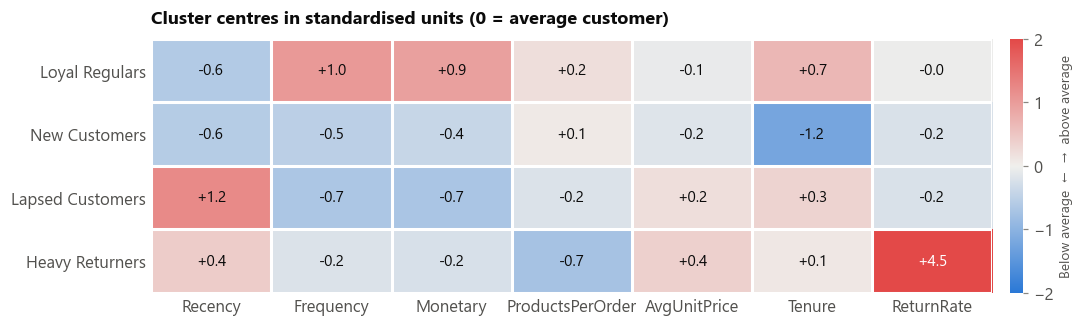

In [6]:
names = {int(k): v for k, v in config["segment_names"].items()}
centres = scaled.groupby(segments["Cluster"]).mean().rename(index=names).loc[ORDER]
heatmap(centres, diverging, -2, 2, "+.1f", "Cluster centres in standardised units (0 = average customer)",
        "Below average  ←  →  above average", figsize=(10, 3.1), white_above=1.5)

| Segment | n | % of sales | Median R / F / M | Mean silhouette |
|---|---|---|---|---|
| **Loyal Regulars** | 2,137 (37%) | **83%** | 33 days / 9 orders / £2,976 | 0.33 |
| **New Customers** | 1,689 (29%) | 7% | 50 days / 2 orders / £542 (tenure 172 days) | 0.26 |
| **Lapsed Customers** | 1,825 (31%) | 6% | 430 days / 1 order / £358 | 0.19 |
| **Heavy Returners** | 201 (3%) | 4% | 276 days / 3 orders / £603 (return rate 37%) | 0.23 |

Mean RFM score by segment is monotone (12.7, 8.4, 5.5 and 7.8 for returners), so the clusters agree with the classic benchmark while adding tenure and returns.

## 9. Explainability

Surrogate random forest trained to predict the K-Means label (5-fold accuracy 97.3%), explained with TreeSHAP. PDP and ICE curves are in the notebook.

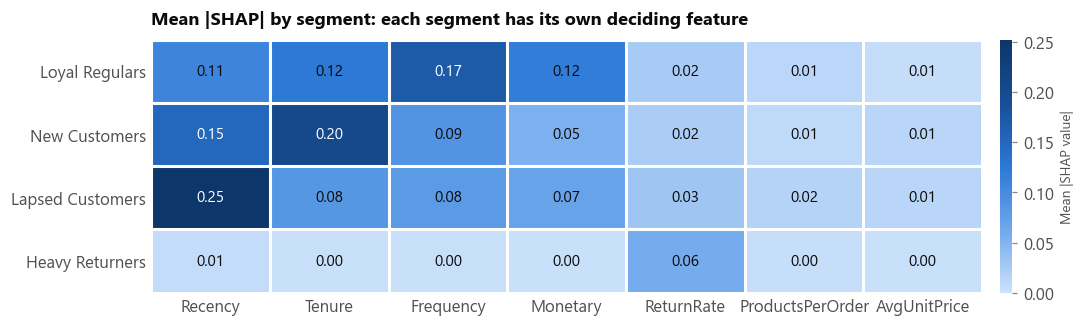

In [7]:
import shap
from sklearn.ensemble import RandomForestClassifier

features = segments[FEATURES].astype(float)
forest = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(features, segments["Segment"])
values = shap.TreeExplainer(forest).shap_values(features.sample(600, random_state=42))
values = np.stack(values, axis=-1) if isinstance(values, list) else np.asarray(values)
importance = pd.DataFrame(np.abs(values).mean(axis=0), index=FEATURES, columns=forest.classes_)[ORDER].T
importance = importance[importance.mean().sort_values(ascending=False).index]
heatmap(importance, sequential, 0, None, ".2f", "Mean |SHAP| by segment: each segment has its own deciding feature",
        "Mean |SHAP value|", figsize=(10, 3.1), white_above=importance.values.max() * 0.5)

- Lapsed is driven by Recency, New by Tenure, Loyal by Frequency, Heavy Returners by ReturnRate alone.
- ProductsPerOrder and AvgUnitPrice contribute almost nothing: candidates for removal in a simpler model.
- PDP: Recency acts as a cliff near 150 to 200 days; Frequency saturates at about 10 orders.

## 10. Bias and fairness audit (UK vs non-UK)

<small>Country is the only personal attribute available and was excluded from the model. Gender, race and age cannot be audited.</small>

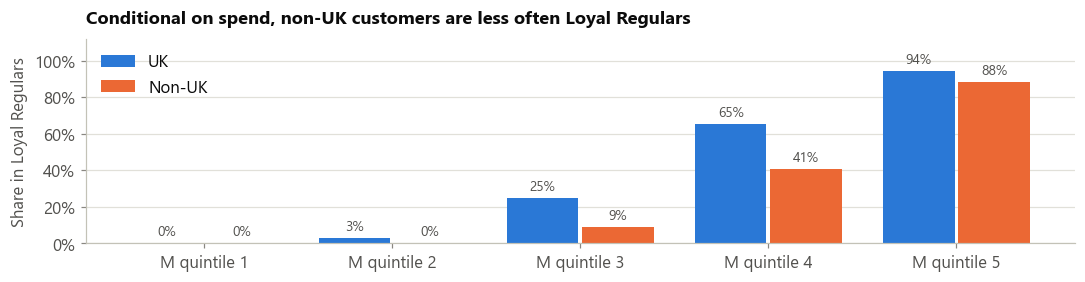

In [8]:
loyal = segments["Segment"] == "Loyal Regulars"
by_grade = (loyal.groupby([segments["M_Score"], segments["Location"]]).mean().unstack() * 100)[["UK", "Non-UK"]]
x = np.arange(len(by_grade))
fig, ax = plt.subplots(figsize=(10, 2.7))
for offset, group, colour in [(-0.2, "UK", BLUE), (0.2, "Non-UK", ORANGE)]:
    bars = ax.bar(x + offset, by_grade[group], width=0.38, color=colour, label=group)
    ax.bar_label(bars, labels=[f"{v:.0f}%" for v in by_grade[group]], padding=3, color=INK_SOFT, fontsize=9)
ax.set_xticks(x, [f"M quintile {g}" for g in by_grade.index]); ax.set_ylim(0, 112)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%")); ax.set_ylabel("Share in Loyal Regulars")
ax.set_title("Conditional on spend, non-UK customers are less often Loyal Regulars")
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

| Metric | Result |
|---|---|
| Demographic parity, Loyal Regulars | 36.7% UK vs 34.4% non-UK; **disparate impact 0.94** (95% interval 0.82 to 1.05) |
| Equalised odds (RFM proxy) | TPR 90.5% vs 91.1%; FPR 21.6% vs 18.7% |
| Conditional disparity | Quintile 4: 65% vs 41%. Non-UK: fewer, larger orders (4 x £461 vs 6 x £319) |
| Why marginal parity still holds | Non-UK customers skew towards higher spend, offsetting the gap |
| Post-processing mitigation | Parity ratio 1.00; quintile 4 gap from 25 to 15 points; +226 customers |

## 11. Limitations, reproducibility and next steps

| Limitation | Evidence or consequence |
|---|---|
| Overlapping clusters | Silhouette 0.265; border customers are ambiguous |
| Selection bias | 15% of sales value has no Customer ID, mostly UK guest checkouts |
| Snapshot dependence | Recency and Tenure are anchored to 10 Dec 2011, just after the seasonal peak |
| Generalisation | 70/30 holdout: ARI 0.992; Silhouette 0.265 vs 0.264 (no overfitting) |
| Surrogate explanations | SHAP explains a 97%-faithful copy, not K-Means itself |
| Descriptive, not causal | Segments do not show that an intervention will work |

**Reproducibility.** Fixed seed (42). Saved in `models/`: scaler, preprocessing and model configs, three fitted models, score tables, fairness audit. Segment assignments in `data/processed/customer_segments.csv`.

**Next steps.** Replace Frequency with orders per year of tenure; drop the two weak features; compare with a Gaussian mixture for soft assignments; refresh quarterly; A/B test campaigns per segment.